In [2]:
!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels scipy

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

import statsmodels.api as sm

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 845

In [4]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

columns = [
    "checking_account",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings",
    "employment_since",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "dependents",
    "telephone",
    "foreign_worker",
    "credit_risk"
]

df = pd.read_csv(
    url,
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset downloaded successfully!")
print(df.head())

Dataset downloaded successfully!
  checking_account  duration credit_history purpose  credit_amount savings  \
0              A11         6            A34     A43           1169     A65   
1              A12        48            A32     A43           5951     A61   
2              A14        12            A34     A46           2096     A61   
3              A11        42            A32     A42           7882     A61   
4              A11        24            A33     A40           4870     A61   

  employment_since  installment_rate personal_status_sex other_debtors  ...  \
0              A75                 4                 A93          A101  ...   
1              A73                 2                 A92          A101  ...   
2              A74                 2                 A93          A101  ...   
3              A74                 2                 A93          A103  ...   
4              A73                 3                 A93          A101  ...   

   property age  other_

In [5]:
print("Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["credit_risk"].value_counts())

Shape: (1000, 21)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   checking_account         1000 non-null   object
 1   duration                 1000 non-null   int64 
 2   credit_history           1000 non-null   object
 3   purpose                  1000 non-null   object
 4   credit_amount            1000 non-null   int64 
 5   savings                  1000 non-null   object
 6   employment_since         1000 non-null   object
 7   installment_rate         1000 non-null   int64 
 8   personal_status_sex      1000 non-null   object
 9   other_debtors            1000 non-null   object
 10  residence_since          1000 non-null   int64 
 11  property                 1000 non-null   object
 12  age                      1000 non-null   int64 
 13  other_installment_plans  1000 non-null   object
 14  h

In [6]:
df["approval"] = df["credit_risk"].map({
    1: 1,
    2: 0
})

df.drop(columns=["credit_risk"], inplace=True)

print(df["approval"].value_counts())

approval
1    700
0    300
Name: count, dtype: int64


In [7]:
X = df.drop(columns=["approval"])
y = df["approval"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical columns:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical columns:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

Features shape: (1000, 20)
Target shape: (1000,)

Numerical columns:
['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'dependents']

Categorical columns:
['checking_account', 'credit_history', 'purpose', 'savings', 'employment_since', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


In [8]:
print("Total missing values:", X.isnull().sum().sum())

Total missing values: 0


In [9]:
numerical_cols = X.select_dtypes(include=np.number).columns

for col in numerical_cols:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((X[col] < lower) | (X[col] > upper)).sum()

    print(f"{col}: {count} potential outliers")

duration: 70 potential outliers
credit_amount: 72 potential outliers
installment_rate: 0 potential outliers
residence_since: 0 potential outliers
age: 23 potential outliers
existing_credits: 6 potential outliers
dependents: 155 potential outliers


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=845,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 700
Testing records: 300


In [11]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numerical_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (700, 48)
Processed testing shape: (300, 48)


In [ ]:
### Data Preprocessing

1. Missing Values: Checked all columns for missing values.
2. Categorical Encoding: Applied One-Hot Encoding with the first category dropped.
3. Feature Scaling: Applied StandardScaler to numerical features.
4. Outliers: Identified potential outliers using the IQR method. They were retained because extreme financial values may represent genuine applicants.
5. Data Splitting: Used 70% training and 30% testing with random_state=845.

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Train Linear Regression
linear_model = LinearRegression()

linear_model.fit(X_train_processed, y_train)

# Predictions
linear_predictions = linear_model.predict(X_test_processed)

# Evaluate
print("Linear Regression Results")
print("R2 Score:", r2_score(y_test, linear_predictions))
print("MSE:", mean_squared_error(y_test, linear_predictions))

print("\nFirst 10 Predictions:")
print(linear_predictions[:10])

Linear Regression Results
R2 Score: 0.21542816074437232
MSE: 0.16476008624368182

First 10 Predictions:
[0.69443011 0.45361869 0.24026893 1.17145643 1.03268486 0.64302493
 0.59714299 0.66007631 0.62841519 0.92302652]


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Train Logistic Regression
logistic_model = LogisticRegression(max_iter=2000)

logistic_model.fit(X_train_processed, y_train)

# Predict probabilities
logistic_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

# Predict classes using 0.5 threshold
logistic_predictions = (
    logistic_probabilities >= 0.5
).astype(int)

print("Logistic Regression Results")

print("Accuracy:",
      accuracy_score(y_test, logistic_predictions))

print("\nClassification Report:")
print(classification_report(y_test, logistic_predictions))

Logistic Regression Results
Accuracy: 0.8

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.52      0.61        90
           1       0.82      0.92      0.87       210

    accuracy                           0.80       300
   macro avg       0.78      0.72      0.74       300
weighted avg       0.79      0.80      0.79       300



In [14]:
from sklearn.metrics import confusion_matrix

# Median threshold for Linear Regression
linear_threshold = np.median(linear_predictions)

# Classify Linear Regression predictions
linear_classes = (
    linear_predictions >= linear_threshold
).astype(int)

# Logistic Regression classification
logistic_classes = (
    logistic_probabilities >= 0.5
).astype(int)

# Compare predictions
cm = confusion_matrix(
    linear_classes,
    logistic_classes,
    labels=[0, 1]
)

print("Linear Regression Median Threshold:",
      linear_threshold)

print("\nConfusion Matrix:")
print(cm)

# Count mismatches
mismatches = np.sum(linear_classes != logistic_classes)

total = len(y_test)

print("\nTotal Test Cases:", total)
print("Mismatched Cases:", mismatches)

print("Mismatch Percentage:",
      round((mismatches / total) * 100, 2), "%")

Linear Regression Median Threshold: 0.7542583171332562

Confusion Matrix:
[[ 64  86]
 [  0 150]]

Total Test Cases: 300
Mismatched Cases: 86
Mismatch Percentage: 28.67 %


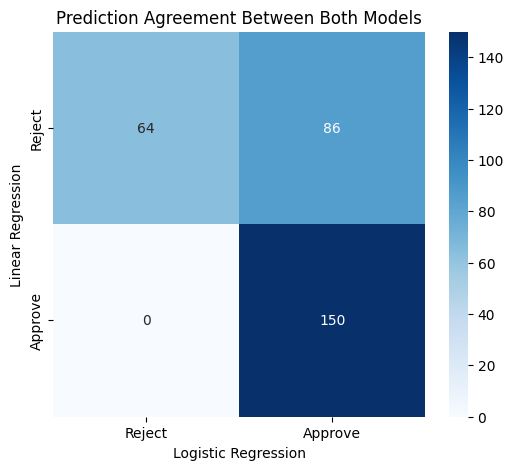

In [15]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Reject", "Approve"],
    yticklabels=["Reject", "Approve"]
)

plt.xlabel("Logistic Regression")
plt.ylabel("Linear Regression")
plt.title("Prediction Agreement Between Both Models")

plt.show()

In [16]:
part1_results = {
    "linear_median_threshold": linear_threshold,
    "mismatches": mismatches,
    "mismatch_percentage": (mismatches / total) * 100,
    "test_cases": total,
    "confusion_matrix": cm.tolist()
}

print(part1_results)

{'linear_median_threshold': np.float64(0.7542583171332562), 'mismatches': np.int64(86), 'mismatch_percentage': np.float64(28.666666666666668), 'test_cases': 300, 'confusion_matrix': [[64, 86], [0, 150]]}


In [17]:
# Find median age in training data
median_age = X_train["age"].median()

# Divide applicants into two groups
group_A_idx = X_train[X_train["age"] < median_age].index
group_B_idx = X_train[X_train["age"] >= median_age].index

print("Median Age:", median_age)

print("Younger Applicants:", len(group_A_idx))
print("Older Applicants:", len(group_B_idx))

Median Age: 33.0
Younger Applicants: 346
Older Applicants: 354


In [18]:
import statsmodels.api as sm

# Function to fit logistic regression
def fit_logistic_model(X_data, y_data):

    # Remove features with no variation in this group
    X_data = X_data.loc[:, X_data.nunique() > 1]

    X_data = sm.add_constant(X_data, has_constant="add")

    model = sm.GLM(
        y_data,
        X_data,
        family=sm.families.Binomial()
    )

    return model.fit(maxiter=200)


# Model 1: Full training dataset
full_model = fit_logistic_model(
    X_train_processed,
    y_train
)

# Model 2: Younger applicants
younger_model = fit_logistic_model(
    X_train_processed.loc[group_A_idx],
    y_train.loc[group_A_idx]
)

# Model 3: Older applicants
older_model = fit_logistic_model(
    X_train_processed.loc[group_B_idx],
    y_train.loc[group_B_idx]
)

print("All three models trained successfully!")

All three models trained successfully!


In [19]:
key_predictor = "num__duration"

results = []

for name, model in [
    ("Full Dataset", full_model),
    ("Younger Applicants", younger_model),
    ("Older Applicants", older_model)
]:

    results.append({
        "Group": name,
        "Coefficient": model.params.get(key_predictor, np.nan),
        "P-value": model.pvalues.get(key_predictor, np.nan),
        "CI Lower": model.conf_int().loc[key_predictor, 0],
        "CI Upper": model.conf_int().loc[key_predictor, 1]
    })

simpson_results = pd.DataFrame(results)

print(simpson_results.round(4).to_string(index=False))

             Group  Coefficient  P-value  CI Lower  CI Upper
      Full Dataset      -0.3592   0.0106   -0.6349   -0.0836
Younger Applicants      -0.4488   0.0370   -0.8704   -0.0271
  Older Applicants      -0.2579   0.2625   -0.7091    0.1932


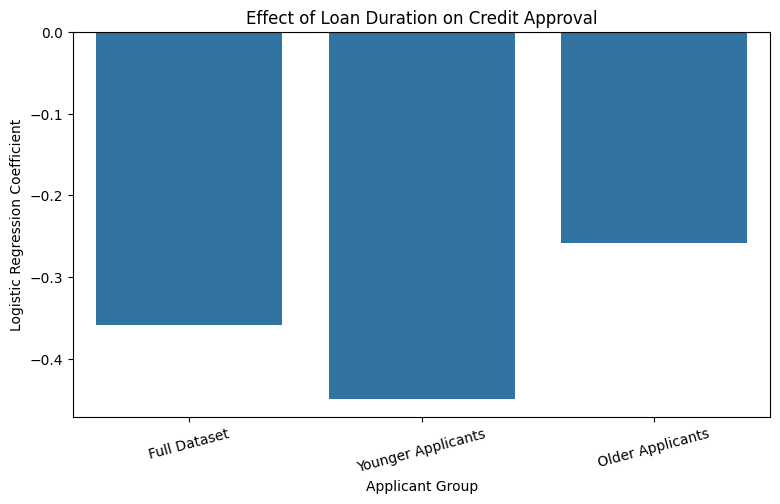

In [20]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=simpson_results,
    x="Group",
    y="Coefficient"
)

plt.axhline(0, color="black", linestyle="--")
plt.title("Effect of Loan Duration on Credit Approval")
plt.ylabel("Logistic Regression Coefficient")
plt.xlabel("Applicant Group")
plt.xticks(rotation=15)

plt.show()

In [21]:
# Full model: All processed features included

ovb_full_model = fit_logistic_model(
    X_train_processed,
    y_train
)

print(ovb_full_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               approval   No. Observations:                  700
Model:                            GLM   Df Residuals:                      651
Model Family:                Binomial   Df Model:                           48
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -312.36
Date:                Wed, 25 Nov 2026   Deviance:                       624.72
Time:                        21:52:16   Pearson chi2:                     646.
No. Iterations:                     6   Pseudo R-squ. (CS):             0.2806
Covariance Type:            nonrobust                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const 

In [22]:
# Remove age from the dataset
X_train_reduced = X_train_processed.drop(
    columns=["num__age"]
)

# Train reduced logistic regression model
ovb_reduced_model = fit_logistic_model(
    X_train_reduced,
    y_train
)

print(ovb_reduced_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               approval   No. Observations:                  700
Model:                            GLM   Df Residuals:                      652
Model Family:                Binomial   Df Model:                           47
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -313.64
Date:                Wed, 25 Nov 2026   Deviance:                       627.27
Time:                        21:52:27   Pearson chi2:                     644.
No. Iterations:                     6   Pseudo R-squ. (CS):             0.2779
Covariance Type:            nonrobust                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const 

In [23]:
# Select four predictors
selected_predictors = [
    "num__duration",
    "num__credit_amount",
    "num__installment_rate",
    "num__existing_credits"
]

comparison = []

for feature in selected_predictors:

    before = ovb_full_model.params[feature]
    after = ovb_reduced_model.params[feature]

    percentage_change = (
        (after - before) / abs(before)
    ) * 100

    comparison.append({
        "Predictor": feature,
        "Before (Full Model)": before,
        "After (Reduced Model)": after,
        "Percentage Change (%)": percentage_change
    })

ovb_results = pd.DataFrame(comparison)

print(ovb_results.round(4).to_string(index=False))

            Predictor  Before (Full Model)  After (Reduced Model)  Percentage Change (%)
        num__duration              -0.3592                -0.3641                -1.3622
   num__credit_amount              -0.3655                -0.3755                -2.7265
num__installment_rate              -0.3642                -0.3562                 2.1979
num__existing_credits              -0.1948                -0.1837                 5.6768


In [24]:
ovb_results["Absolute Change"] = abs(
    ovb_results["After (Reduced Model)"] -
    ovb_results["Before (Full Model)"]
)

largest_shift = ovb_results.loc[
    ovb_results["Absolute Change"].idxmax()
]

print("Predictor with the largest coefficient shift:")
print(largest_shift)

Predictor with the largest coefficient shift:
Predictor                num__existing_credits
Before (Full Model)                  -0.194757
After (Reduced Model)                -0.183701
Percentage Change (%)                 5.676805
Absolute Change                       0.011056
Name: 3, dtype: object


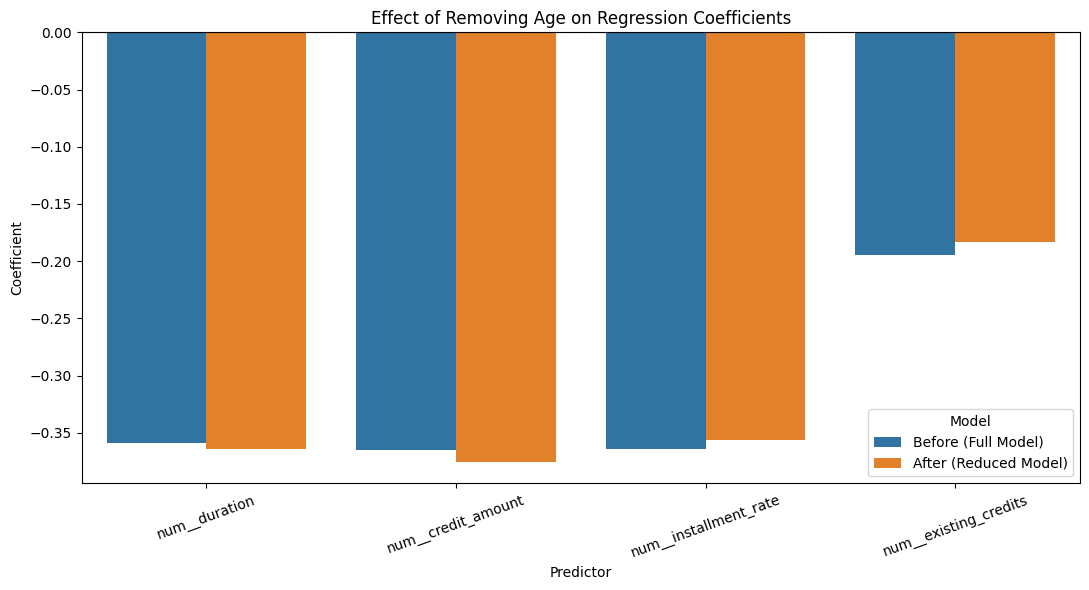

In [25]:
plot_data = ovb_results.melt(
    id_vars="Predictor",
    value_vars=[
        "Before (Full Model)",
        "After (Reduced Model)"
    ],
    var_name="Model",
    value_name="Coefficient"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_data,
    x="Predictor",
    y="Coefficient",
    hue="Model"
)

plt.axhline(0, color="black", linestyle="--")
plt.title("Effect of Removing Age on Regression Coefficients")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [26]:
# Combine actual outcomes and predicted probabilities

adversarial_df = pd.DataFrame({
    "actual": y_test,
    "predicted_probability": logistic_probabilities
}, index=y_test.index)

print(adversarial_df.head())

     actual  predicted_probability
114       1               0.714277
513       1               0.392690
221       1               0.205915
778       1               0.982209
361       1               0.945344


In [27]:
# False positives: confident approval, actual rejection
false_positives = adversarial_df[
    (adversarial_df["predicted_probability"] >= 0.75) &
    (adversarial_df["actual"] == 0)
]

# False negatives: confident rejection, actual approval
false_negatives = adversarial_df[
    (adversarial_df["predicted_probability"] <= 0.25) &
    (adversarial_df["actual"] == 1)
]

# Combine both
high_confidence_errors = pd.concat([
    false_positives,
    false_negatives
])

print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))
print("Total High-Confidence Errors:", len(high_confidence_errors))

print(
    "Percentage of test set:",
    round(len(high_confidence_errors) / len(y_test) * 100, 2),
    "%"
)

False Positives: 25
False Negatives: 2
Total High-Confidence Errors: 27
Percentage of test set: 9.0 %


In [28]:
if len(high_confidence_errors) > 50:
    adversarial_sample = high_confidence_errors.sample(
        n=50,
        random_state=845
    )
else:
    adversarial_sample = high_confidence_errors.copy()

print("Selected adversarial cases:", len(adversarial_sample))

print(adversarial_sample.head(10))

Selected adversarial cases: 27
     actual  predicted_probability
598       0               0.939401
900       0               0.868707
645       0               0.799357
674       0               0.910724
842       0               0.803317
763       0               0.875573
963       0               0.873041
278       0               0.896915
720       0               0.893715
190       0               0.975714


In [29]:
# Get original test dataset for selected cases
adversarial_demographics = X_test.loc[
    adversarial_sample.index
].copy()

# Add actual outcome and predicted probability
adversarial_demographics["actual"] = (
    adversarial_sample["actual"]
)

adversarial_demographics["predicted_probability"] = (
    adversarial_sample["predicted_probability"]
)

print(adversarial_demographics.head())

    checking_account  duration credit_history purpose  credit_amount savings  \
598              A14        18            A34     A40           2775     A61   
900              A11        16            A34     A40           2625     A61   
645              A14        36            A33     A49           7980     A65   
674              A14        21            A33     A49           2580     A63   
842              A14        18            A32     A45           1943     A61   

    employment_since  installment_rate personal_status_sex other_debtors  ...  \
598              A74                 2                 A93          A101  ...   
900              A75                 2                 A93          A103  ...   
645              A72                 4                 A93          A101  ...   
674              A72                 4                 A93          A101  ...   
842              A72                 4                 A92          A101  ...   

     age other_installment_plans

In [30]:
age_comparison = pd.DataFrame({
    "Full Test Set": [
        X_test["age"].mean(),
        X_test["age"].median()
    ],
    "Adversarial Subset": [
        adversarial_demographics["age"].mean(),
        adversarial_demographics["age"].median()
    ]
}, index=["Mean Age", "Median Age"])

print(age_comparison.round(2))

            Full Test Set  Adversarial Subset
Mean Age            35.65               36.48
Median Age          34.00               34.00


In [31]:
print("Full Test Set:")
print(
    X_test["personal_status_sex"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nAdversarial Subset:")
print(
    adversarial_demographics["personal_status_sex"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Full Test Set:
personal_status_sex
A93    57.00
A92    29.00
A94     9.33
A91     4.67
Name: proportion, dtype: float64

Adversarial Subset:
personal_status_sex
A93    70.37
A92    18.52
A94    11.11
Name: proportion, dtype: float64


In [32]:
numeric_comparison = pd.DataFrame({
    "Full Test Mean": X_test[
        ["duration", "credit_amount", "installment_rate", "age"]
    ].mean(),

    "Adversarial Mean": adversarial_demographics[
        ["duration", "credit_amount", "installment_rate", "age"]
    ].mean()
})

print(numeric_comparison.round(2))

                  Full Test Mean  Adversarial Mean
duration                   21.34             20.96
credit_amount            3383.70           4250.85
installment_rate            2.94              3.04
age                        35.65             36.48


In [33]:
categorical_features = [
    "credit_history",
    "purpose",
    "employment_since",
    "checking_account"
]

for col in categorical_features:

    print("\nFeature:", col)

    print("\nFull Test Set (%):")
    print(
        X_test[col]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    print("\nAdversarial Subset (%):")
    print(
        adversarial_demographics[col]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )


Feature: credit_history

Full Test Set (%):
credit_history
A32    54.67
A34    28.00
A33     8.67
A31     4.67
A30     4.00
Name: proportion, dtype: float64

Adversarial Subset (%):
credit_history
A34    29.63
A33    29.63
A32    29.63
A30     7.41
A31     3.70
Name: proportion, dtype: float64

Feature: purpose

Full Test Set (%):
purpose
A43     27.33
A40     24.00
A42     16.33
A41     12.33
A49      8.00
A46      6.33
A45      3.33
A44      1.00
A410     0.67
A48      0.67
Name: proportion, dtype: float64

Adversarial Subset (%):
purpose
A43    25.93
A40    22.22
A49    18.52
A45    11.11
A46    11.11
A42     7.41
A41     3.70
Name: proportion, dtype: float64

Feature: employment_since

Full Test Set (%):
employment_since
A73    32.00
A75    29.33
A72    16.67
A74    16.67
A71     5.33
Name: proportion, dtype: float64

Adversarial Subset (%):
employment_since
A73    29.63
A74    22.22
A72    22.22
A75    18.52
A71     7.41
Name: proportion, dtype: float64

Feature: checking_account

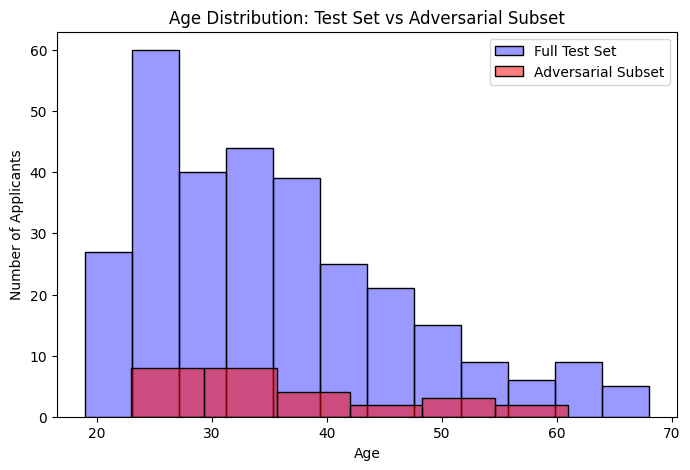

In [34]:
plt.figure(figsize=(8, 5))

sns.histplot(
    X_test["age"],
    label="Full Test Set",
    color="blue",
    alpha=0.4
)

sns.histplot(
    adversarial_demographics["age"],
    label="Adversarial Subset",
    color="red",
    alpha=0.5
)

plt.title("Age Distribution: Test Set vs Adversarial Subset")
plt.xlabel("Age")
plt.ylabel("Number of Applicants")
plt.legend()
plt.show()

In [35]:
adversarial_sample.to_csv(
    "adversarial_subset.csv",
    index=True
)

adversarial_results = {
    "false_positives": len(false_positives),
    "false_negatives": len(false_negatives),
    "total_errors": len(high_confidence_errors),
    "error_percentage": (
        len(high_confidence_errors) / len(y_test)
    ) * 100,
    "selected_cases": len(adversarial_sample)
}

print(adversarial_results)

{'false_positives': 25, 'false_negatives': 2, 'total_errors': 27, 'error_percentage': 9.0, 'selected_cases': 27}


In [36]:
# Use the same median age calculated earlier

test_groups = pd.Series(
    np.where(
        X_test["age"] < median_age,
        "Group A - Younger",
        "Group B - Older"
    ),
    index=X_test.index
)

print(test_groups.value_counts())

Group B - Older      163
Group A - Younger    137
Name: count, dtype: int64


In [37]:
def calculate_group_metrics(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    total = tn + fp + fn + tp

    selection_rate = (tp + fp) / total if total else np.nan

    tpr = tp / (tp + fn) if (tp + fn) else np.nan

    fpr = fp / (fp + tn) if (fp + tn) else np.nan

    precision = tp / (tp + fp) if (tp + fp) else np.nan

    return {
        "DP_rate": selection_rate,
        "TPR": tpr,
        "FPR": fpr,
        "PP_rate": precision
    }


def safe_ratio(a, b):

    if pd.isna(a) or pd.isna(b) or b == 0:
        return np.nan

    return a / b

In [38]:
thresholds = np.round(
    np.arange(0.05, 1.00, 0.10),
    2
)

fairness_results = []

for threshold in thresholds:

    # Classification based on current threshold
    predictions = (
        logistic_probabilities >= threshold
    ).astype(int)

    # Extract each demographic group
    mask_A = test_groups == "Group A - Younger"
    mask_B = test_groups == "Group B - Older"

    metrics_A = calculate_group_metrics(
        y_test[mask_A],
        predictions[mask_A]
    )

    metrics_B = calculate_group_metrics(
        y_test[mask_B],
        predictions[mask_B]
    )

    # Calculate fairness metrics
    dp = safe_ratio(
        metrics_A["DP_rate"],
        metrics_B["DP_rate"]
    )

    eo_tpr = safe_ratio(
        metrics_A["TPR"],
        metrics_B["TPR"]
    )

    eo_fpr = safe_ratio(
        metrics_A["FPR"],
        metrics_B["FPR"]
    )

    eo = (
        min(eo_tpr, eo_fpr)
        if not pd.isna(eo_tpr) and not pd.isna(eo_fpr)
        else np.nan
    )

    pp = safe_ratio(
        metrics_A["PP_rate"],
        metrics_B["PP_rate"]
    )

    fairness_results.append({
        "Threshold": threshold,
        "DP": dp,
        "EO": eo,
        "PP": pp,
        "TPR_A": metrics_A["TPR"],
        "TPR_B": metrics_B["TPR"],
        "FPR_A": metrics_A["FPR"],
        "FPR_B": metrics_B["FPR"]
    })

fairness_df = pd.DataFrame(fairness_results)

print(fairness_df.round(4).to_string(index=False))

 Threshold     DP     EO     PP  TPR_A  TPR_B  FPR_A  FPR_B
      0.05 1.0062 1.0000 0.8869 1.0000 1.0000 1.0000 0.9767
      0.15 1.0091 1.0000 0.8843 1.0000 1.0000 0.9362 0.8837
      0.25 0.9762 0.9778 0.8938 0.9778 1.0000 0.8511 0.8372
      0.35 0.9201 0.9333 0.9052 0.9333 1.0000 0.6809 0.6977
      0.45 0.8123 0.7390 0.9600 0.8667 0.9917 0.4468 0.6047
      0.55 0.7961 0.6762 0.9787 0.8222 0.9417 0.3617 0.5349
      0.65 0.7710 0.6608 0.9807 0.7556 0.8917 0.2766 0.4186
      0.75 0.6598 0.6099 0.9681 0.5667 0.7917 0.2128 0.3488
      0.85 0.6384 0.6404 0.9577 0.4111 0.6000 0.1489 0.2326
      0.95 0.5769 0.3050 1.0312 0.1667 0.2500 0.0213 0.0698


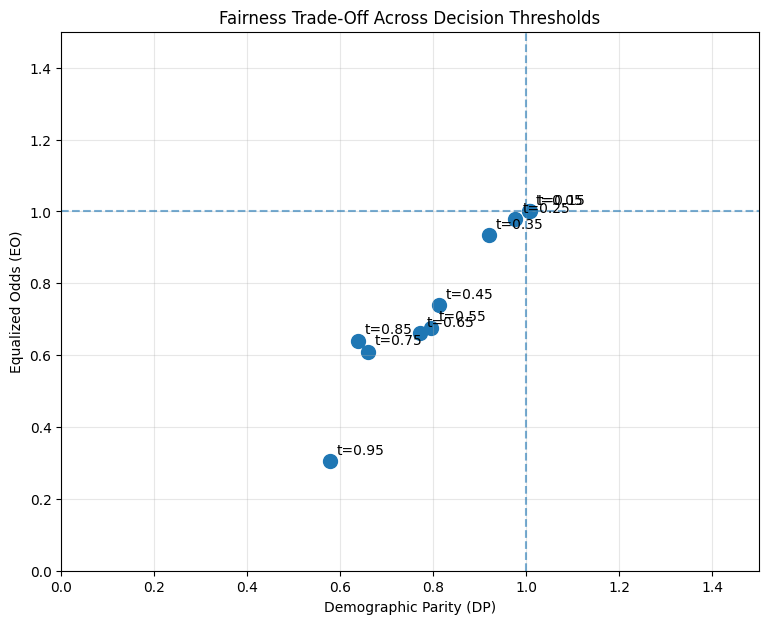

In [39]:
plt.figure(figsize=(9, 7))

valid_points = fairness_df.dropna(
    subset=["DP", "EO"]
)

plt.scatter(
    valid_points["DP"],
    valid_points["EO"],
    s=100
)

for _, row in valid_points.iterrows():

    plt.annotate(
        f"t={row['Threshold']:.2f}",
        (row["DP"], row["EO"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axvline(1, linestyle="--", alpha=0.6)
plt.axhline(1, linestyle="--", alpha=0.6)

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)

plt.xlabel("Demographic Parity (DP)")
plt.ylabel("Equalized Odds (EO)")

plt.title("Fairness Trade-Off Across Decision Thresholds")

plt.grid(alpha=0.3)
plt.show()

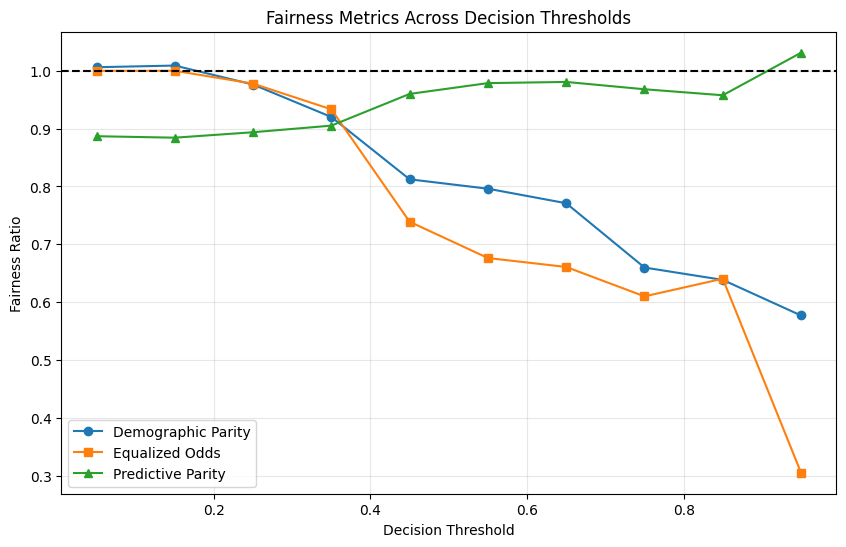

In [40]:
plt.figure(figsize=(10, 6))

plt.plot(
    fairness_df["Threshold"],
    fairness_df["DP"],
    marker="o",
    label="Demographic Parity"
)

plt.plot(
    fairness_df["Threshold"],
    fairness_df["EO"],
    marker="s",
    label="Equalized Odds"
)

plt.plot(
    fairness_df["Threshold"],
    fairness_df["PP"],
    marker="^",
    label="Predictive Parity"
)

plt.axhline(1, linestyle="--", color="black")

plt.xlabel("Decision Threshold")
plt.ylabel("Fairness Ratio")

plt.title("Fairness Metrics Across Decision Thresholds")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [41]:
valid_tradeoff = fairness_df.dropna(
    subset=["DP", "EO"]
)

best_dp_row = valid_tradeoff.loc[
    valid_tradeoff["DP"].idxmin()
]

worst_dp_row = valid_tradeoff.loc[
    valid_tradeoff["DP"].idxmax()
]

print("Lowest DP:")
print(best_dp_row)

print("\nHighest DP:")
print(worst_dp_row)

Lowest DP:
Threshold    0.950000
DP           0.576864
EO           0.304965
PP           1.031250
TPR_A        0.166667
TPR_B        0.250000
FPR_A        0.021277
FPR_B        0.069767
Name: 9, dtype: float64

Highest DP:
Threshold    0.150000
DP           1.009055
EO           1.000000
PP           0.884328
TPR_A        1.000000
TPR_B        1.000000
FPR_A        0.936170
FPR_B        0.883721
Name: 1, dtype: float64


In [42]:
dp_gain = (
    (worst_dp_row["DP"] - best_dp_row["DP"])
    / abs(best_dp_row["DP"])
) * 100

eo_change = (
    (worst_dp_row["EO"] - best_dp_row["EO"])
    / abs(best_dp_row["EO"])
) * 100

print("DP change (%):", round(dp_gain, 2))
print("EO change (%):", round(eo_change, 2))

DP change (%): 74.92
EO change (%): 227.91


In [43]:
fairness_df.to_csv(
    "fairness_results.csv",
    index=False
)

print("Fairness results saved successfully!")

Fairness results saved successfully!


In [44]:
print("=" * 50)
print("PART 1 RESULTS")
print("=" * 50)

print(part1_results)

print("\n" + "=" * 50)
print("PART 2.1 - SIMPSON'S PARADOX")
print("=" * 50)

print(simpson_results.round(4))

print("\n" + "=" * 50)
print("PART 2.2 - OMITTED VARIABLE BIAS")
print("=" * 50)

print(ovb_results.round(4))

print("\n" + "=" * 50)
print("PART 2.3 - ADVERSARIAL SUBSET")
print("=" * 50)

print(adversarial_results)

print("\n" + "=" * 50)
print("PART 2.4 - FAIRNESS ANALYSIS")
print("=" * 50)

print(fairness_df.round(4))

PART 1 RESULTS
{'linear_median_threshold': np.float64(0.7542583171332562), 'mismatches': np.int64(86), 'mismatch_percentage': np.float64(28.666666666666668), 'test_cases': 300, 'confusion_matrix': [[64, 86], [0, 150]]}

PART 2.1 - SIMPSON'S PARADOX
                Group  Coefficient  P-value  CI Lower  CI Upper
0        Full Dataset      -0.3592   0.0106   -0.6349   -0.0836
1  Younger Applicants      -0.4488   0.0370   -0.8704   -0.0271
2    Older Applicants      -0.2579   0.2625   -0.7091    0.1932

PART 2.2 - OMITTED VARIABLE BIAS
               Predictor  Before (Full Model)  After (Reduced Model)  \
0          num__duration              -0.3592                -0.3641   
1     num__credit_amount              -0.3655                -0.3755   
2  num__installment_rate              -0.3642                -0.3562   
3  num__existing_credits              -0.1948                -0.1837   

   Percentage Change (%)  Absolute Change  
0                -1.3622           0.0049  
1           